In [11]:
# Code needed to save the graphs into a png for later

from pathlib import Path
from unittest.mock import patch
import matplotlib.pyplot as plt


def save_graph(plot_function, model, x=None, output_root="saved_graphs"):
    folder = Path(output_root) / plot_function.__name__
    folder.mkdir(parents=True, exist_ok=True)

    if x is None:
        sequence = None
        filename = "weights.png"
    else:
        sequence = x.detach().cpu().tolist()[0]
        filename = f"{sequence}.png"

    output_path = folder / filename
    original_show = plt.show

    def save_then_show(*args, **kwargs):
        fig = plt.gcf()

        if sequence is not None:
            fig.suptitle(f"Input: {sequence}", fontsize=10)

        fig.tight_layout()

        if output_path.exists():
            print(f"Already saved: {output_path}")
        else:
            fig.savefig(output_path, dpi=200, bbox_inches="tight")
            print(f"Saved: {output_path}")

        return original_show(*args, **kwargs)

    with patch.object(plt, "show", side_effect=save_then_show):
        if x is None:
            plot_function(model)
        else:
            plot_function(x, model)

    return output_path

# Exploring the Model’s Weights

## 1. Original Weights

These plots show the model’s existing weights before rescaling.
Each square’s color represents the value of a weight.

In [ ]:
#Run cell once before being able to plot weights
from alg_zoo import example_2nd_argmax
from helpers import plot_weights

model = example_2nd_argmax()


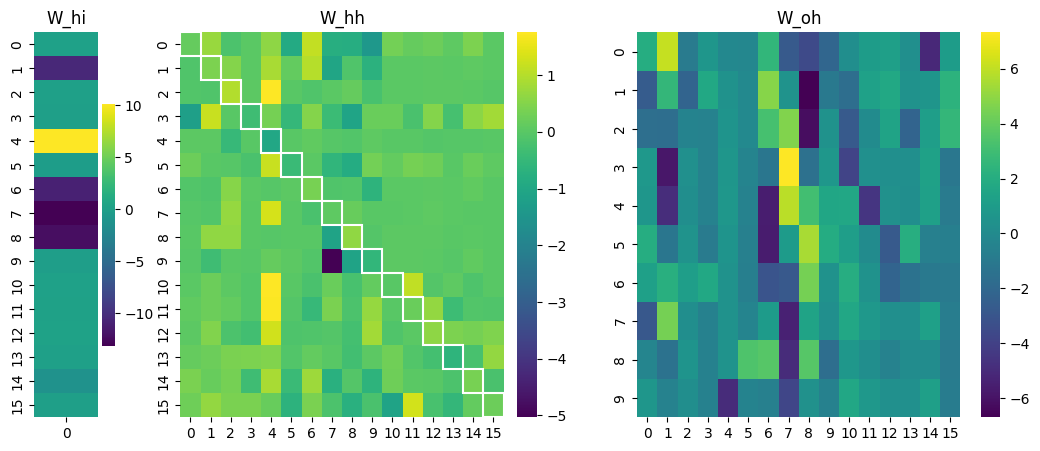

In [ ]:
# Run every other time to reset the weight model
plot_weights(model)

## 2. Hidden-State Evolution

This heatmap shows each hidden neuron’s activation after each number
in the input sequence is processed. It lets us follow how the model’s
internal state changes throughout the sequence.

In [47]:
#Run once everytime to import everything, then once after that only when wanting to change the inputs
import torch as th
from helpers import hidden_state_evolution

x = th.tensor(
    [[0, 0, 0, 0, 0, 0, 0, 0, 8, 5]],
    dtype=th.float32
    )

Saved: saved_graphs\hidden_state_evolution\[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 8.0, 5.0].png


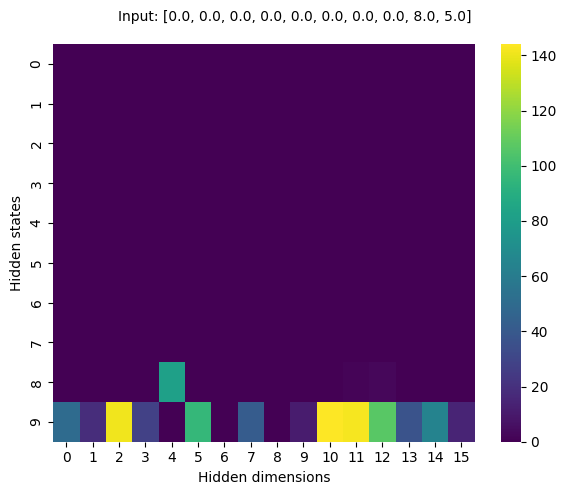

In [48]:
# Run code ONLY when wanting to save the output provided in the graph above
saved_path = save_graph(hidden_state_evolution, model, x=x)

## 3. Output Scores and Prediction

This heatmap shows the scores assigned to the possible output indices.
The highest-scoring index is the model’s prediction for the location
of the second-largest number in the sequence.

Saved: saved_graphs\plot_logits\[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 8.0, 5.0].png


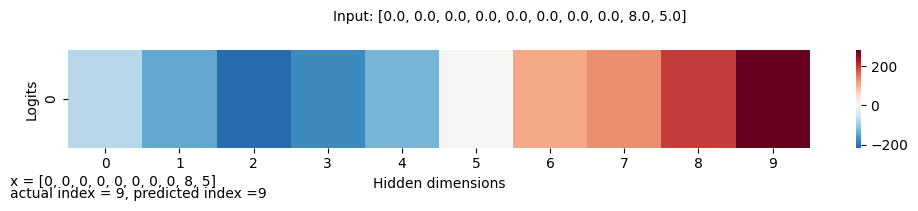

In [49]:
from helpers import plot_logits

saved_path = save_graph(plot_logits, model, x=x)

## 4. Rescaled Weights

These plots show rescaled versions of the input-to-hidden,
hidden-to-hidden, and hidden-to-output weight matrices.

The input weights become +1 or −1, and the other matrices are
adjusted accordingly. This helps us examine connections between
neurons on a different scale.

Already saved: saved_graphs\plot_weights_rescaled\weights.png


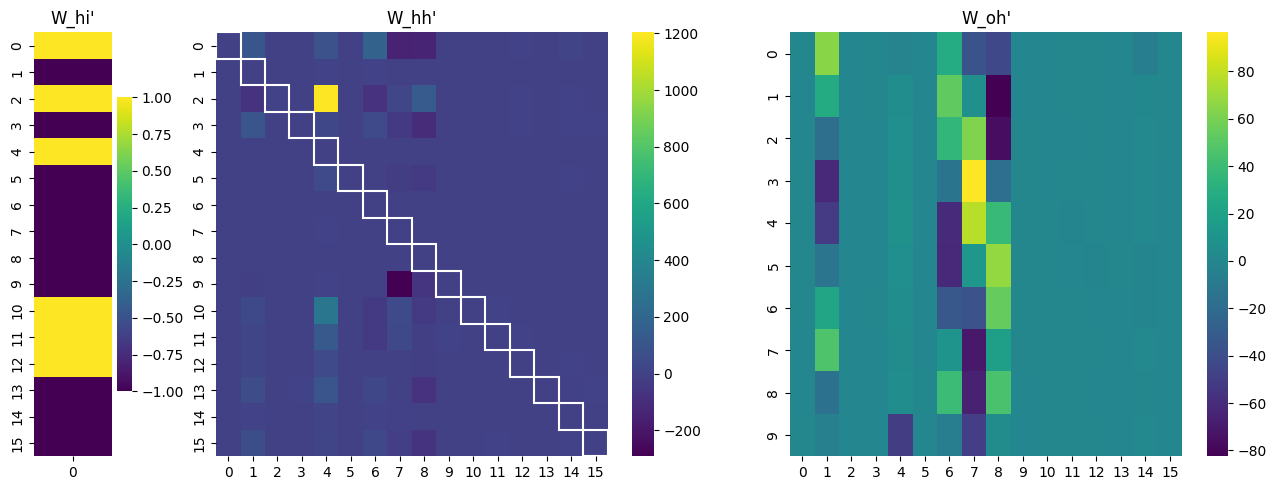

In [50]:
from helpers import plot_weights_rescaled

saved_path = save_graph(plot_weights_rescaled, model)